# Prueba 03-2

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import UpROOT.io as io
import UpROOT.config as conf
import UpROOT.physics.delphes as ph
import UpROOT.plotting.delphes as pt
import UpROOT.pipelines.delphes as pl
import UpROOT.fitting.delphes as fi
import UpROOT.delphes_root as dr

In [3]:
ANALYSIS = 'smf03'
cfg = conf.CONFIGURATIONS[ANALYSIS]
DATASET = cfg['raw_dataset']
PDATASET = cfg['flat_dataset']
PLOT_DATA = cfg['plot_data']
TARGET_MASS = None
MASS_RANGE = cfg['mass_range']
FIT_WINDOW = cfg['fit_window']
MIN_MUON_PT = 0.0
ETA_RANGE = (2.0, 5.0)

plot_options = {
    'save': True,
    'data': PLOT_DATA,
    'output_dir': None
}

In [4]:
# cut = '(Eta < 5.0) & (Eta > 2)'
MUON_BRANCHES = (
    'event_id',
    'object_index',
    'PT',
    'Eta',
    'Phi',
    'Charge',
    'D0',
    'DZ',
    'ErrorD0',
    'ErrorDZ',
    'IsolationVar',
    'Particle_ref'
)

In [6]:
df_events = io.load_dataframe(
    branches=None,
    dataset=PDATASET,
    tree_path='Events',
)
df_events.head()

Archivo: dimuons03_pandas.root
Árbol seleccionado: Events
Total de eventos: 400,000 eventos


,source_file_id,event_id,source_entry,root_uid,event_number,ReadTime,ProcTime,ProcessID,MPI,event_weight,...,PDF1,PDF2,n_EFlowTrack,n_Electron,n_Jet,n_Muon,n_Particle,n_ScalarHT,n_Track,n_Weight
0,0,0,0,0,0,0.506989,0.009800,9999,-1,40990.117188,...,inf,inf,3,0,0,2,578,1,11,292
1,0,1,1,0,1,0.001399,0.001059,9999,-1,35096.382812,...,inf,inf,0,0,0,0,251,1,1,292
2,0,2,2,0,2,0.001357,0.000654,9999,-1,60.626938,...,inf,inf,1,0,0,0,221,1,3,292
3,0,3,3,0,3,0.000561,0.000407,9999,-1,35002.351562,...,inf,inf,0,0,0,0,130,1,0,292
4,0,4,4,0,4,0.002827,0.001104,9999,-1,-0.028055,...,inf,inf,2,0,0,0,642,1,13,292


In [7]:
df_muons = io.load_dataframe(
    branches=MUON_BRANCHES,
    dataset=PDATASET,
    tree_path='Muons'
)
df_muons.head(7)

Archivo: dimuons03_pandas.root
Árbol seleccionado: Muons
Total de eventos: 155,861 eventos


,event_id,object_index,PT,Eta,Phi,Charge,D0,DZ,ErrorD0,ErrorDZ,IsolationVar,Particle_ref
0,0,0,1.118285,3.036834,2.304429,-1,-0.028890,0.0,-0.006414,0.0,0.126076,158
1,0,1,0.894197,3.715472,-1.409537,1,-0.062964,0.0,-0.017734,0.0,0.136532,157
2,5,0,4.271610,4.196128,2.580735,1,-0.007288,0.0,0.022104,0.0,0.000000,96
3,5,1,0.929687,3.645410,-1.688336,-1,-0.008104,0.0,0.008238,0.0,0.000000,97
4,7,0,0.919755,3.423170,2.048764,-1,-0.057072,0.0,-0.000494,0.0,0.000000,16
5,11,0,1.303808,3.976871,-1.248847,-1,-0.063595,0.0,-0.016322,0.0,0.000000,48
6,15,0,1.733335,3.302351,2.582864,1,-0.013200,0.0,0.028962,0.0,0.000000,93


In [8]:
cdf_muons = df_muons.loc[
    df_muons['PT'].ge(MIN_MUON_PT) & 
    df_muons['Eta'].between(*ETA_RANGE)
].copy()
print(f'Muones totales:       {len(df_muons):,}')
print(f'Muones seleccionados: {len(cdf_muons):,}')

Muones totales:       155,861
Muones seleccionados: 155,861


In [9]:
df_muons = ph.calc_four_momentum(df_muons)
df_muons.head()

,event_id,object_index,PT,Eta,Phi,Charge,D0,DZ,ErrorD0,ErrorDZ,IsolationVar,Particle_ref,PX,PY,PZ,P,E
0,0,0,1.118285,3.036834,2.304429,-1,-0.028890,0.0,-0.006414,0.0,0.126076,158,-0.748772,0.830603,11.625232,11.678895,11.679373
1,0,1,0.894197,3.715472,-1.409537,1,-0.062964,0.0,-0.017734,0.0,0.136532,157,0.143573,-0.882595,18.355015,18.376783,18.377087
2,5,0,4.271610,4.196128,2.580735,1,-0.007288,0.0,0.022104,0.0,0.000000,96,-3.617196,2.272123,141.846406,141.910710,141.910749
3,5,1,0.929687,3.645410,-1.688336,-1,-0.008104,0.0,0.008238,0.0,0.000000,97,-0.109023,-0.923272,17.790652,17.814927,17.815240
4,7,0,0.919755,3.423170,2.048764,-1,-0.057072,0.0,-0.000494,0.0,0.000000,16,-0.423065,0.816680,14.087832,14.117825,14.118220


In [10]:
cdf_muons = ph.calc_four_momentum(cdf_muons)
cdf_muons.head()

,event_id,object_index,PT,Eta,Phi,Charge,D0,DZ,ErrorD0,ErrorDZ,IsolationVar,Particle_ref,PX,PY,PZ,P,E
0,0,0,1.118285,3.036834,2.304429,-1,-0.028890,0.0,-0.006414,0.0,0.126076,158,-0.748772,0.830603,11.625232,11.678895,11.679373
1,0,1,0.894197,3.715472,-1.409537,1,-0.062964,0.0,-0.017734,0.0,0.136532,157,0.143573,-0.882595,18.355015,18.376783,18.377087
2,5,0,4.271610,4.196128,2.580735,1,-0.007288,0.0,0.022104,0.0,0.000000,96,-3.617196,2.272123,141.846406,141.910710,141.910749
3,5,1,0.929687,3.645410,-1.688336,-1,-0.008104,0.0,0.008238,0.0,0.000000,97,-0.109023,-0.923272,17.790652,17.814927,17.815240
4,7,0,0.919755,3.423170,2.048764,-1,-0.057072,0.0,-0.000494,0.0,0.000000,16,-0.423065,0.816680,14.087832,14.117825,14.118220


In [11]:
df_dimuons = ph.prepare_dimuon_analysis(
    df_muons, 
    events=df_events,
    min_muon_pt=MIN_MUON_PT,
    classify_displacement=True,
    prompt_max_significance=3.0,
    displaced_min_significance=5.0
)
df_dimuons.head()

,event_id,muplus_index,muplus_pt,muplus_eta,muplus_phi,muplus_charge,muplus_d0,muplus_dz,muplus_error_d0,muplus_error_dz,...,dimuon_rapidity,cos_theta_star,muplus_d0_significance,muminus_d0_significance,muplus_chi2_ip_proxy,muminus_chi2_ip_proxy,sqrt_min_chi2_ip_proxy,min_chi2_ip_proxy,ip_proxy_valid,displacement_category
0,0,1,0.894197,3.715472,-1.409537,1,-0.062964,0.0,-0.017734,0.0,...,3.334593,-0.326869,NaN,NaN,NaN,NaN,NaN,NaN,False,invalid
1,5,0,4.271610,4.196128,2.580735,1,-0.007288,0.0,0.022104,0.0,...,4.093110,-0.268604,0.329709,0.983657,0.108708,0.967582,0.329709,0.108708,True,prompt
2,15,0,1.733335,3.302351,2.582864,1,-0.013200,0.0,0.028962,0.0,...,3.838550,0.545965,0.455772,NaN,0.207728,NaN,NaN,NaN,False,invalid
3,21,0,4.213566,3.521155,2.526603,1,0.040786,0.0,-0.010319,0.0,...,3.256416,-0.319913,NaN,0.612421,NaN,0.375059,NaN,NaN,False,invalid
4,27,0,2.000266,3.616623,-0.761206,1,0.017056,0.0,-0.001670,0.0,...,3.459056,-0.212273,NaN,0.942562,NaN,0.888424,NaN,NaN,False,invalid


In [12]:
display(df_dimuons[[
    "event_id", "dimuon_mass", "dimuon_pt", "delta_r",
    "sqrt_min_chi2_ip_proxy", "min_chi2_ip_proxy",
    "ip_proxy_valid", "displacement_category"
]].head())

,event_id,dimuon_mass,dimuon_pt,delta_r,sqrt_min_chi2_ip_proxy,min_chi2_ip_proxy,ip_proxy_valid,displacement_category
0,0,2.050996,0.607428,2.657336,NaN,NaN,False,invalid
1,5,3.563316,3.962841,2.088049,0.329709,0.108708,True,prompt
2,15,2.197082,2.902675,1.379671,NaN,NaN,False,invalid
3,21,7.073753,1.947073,2.840648,NaN,NaN,False,invalid
4,27,2.872550,1.378653,2.457573,NaN,NaN,False,invalid


In [13]:
display(
    df_dimuons['displacement_category']
    .value_counts(dropna=False)
    .rename('candidatos')
)

displacement_category
invalid      33861
prompt        6923
mixed         3841
displaced      178
Name: candidatos, dtype: int64

In [14]:
cdf_dimuons = ph.prepare_dimuon_analysis(
    cdf_muons, 
    events=df_events,
    min_muon_pt=MIN_MUON_PT,
    classify_displacement=True,
    prompt_max_significance=3.0,
    displaced_min_significance=5.0
)
cdf_dimuons.head(7)

,event_id,muplus_index,muplus_pt,muplus_eta,muplus_phi,muplus_charge,muplus_d0,muplus_dz,muplus_error_d0,muplus_error_dz,...,dimuon_rapidity,cos_theta_star,muplus_d0_significance,muminus_d0_significance,muplus_chi2_ip_proxy,muminus_chi2_ip_proxy,sqrt_min_chi2_ip_proxy,min_chi2_ip_proxy,ip_proxy_valid,displacement_category
0,0,1,0.894197,3.715472,-1.409537,1,-0.062964,0.0,-0.017734,0.0,...,3.334593,-0.326869,NaN,NaN,NaN,NaN,NaN,NaN,False,invalid
1,5,0,4.271610,4.196128,2.580735,1,-0.007288,0.0,0.022104,0.0,...,4.093110,-0.268604,0.329709,0.983657,0.108708,0.967582,0.329709,0.108708,True,prompt
2,15,0,1.733335,3.302351,2.582864,1,-0.013200,0.0,0.028962,0.0,...,3.838550,0.545965,0.455772,NaN,0.207728,NaN,NaN,NaN,False,invalid
3,21,0,4.213566,3.521155,2.526603,1,0.040786,0.0,-0.010319,0.0,...,3.256416,-0.319913,NaN,0.612421,NaN,0.375059,NaN,NaN,False,invalid
4,27,0,2.000266,3.616623,-0.761206,1,0.017056,0.0,-0.001670,0.0,...,3.459056,-0.212273,NaN,0.942562,NaN,0.888424,NaN,NaN,False,invalid
5,51,0,2.967119,2.357656,1.848857,1,-0.024062,0.0,-0.015057,0.0,...,2.582958,0.223485,NaN,8.412769,NaN,70.774679,NaN,NaN,False,invalid
6,52,0,1.127463,4.665898,-3.077994,1,-0.046854,0.0,0.033020,0.0,...,4.708883,0.049239,1.418963,NaN,2.013457,NaN,NaN,NaN,False,invalid


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\smf_model\c03\event_multiplicities_70GeV_01.png.


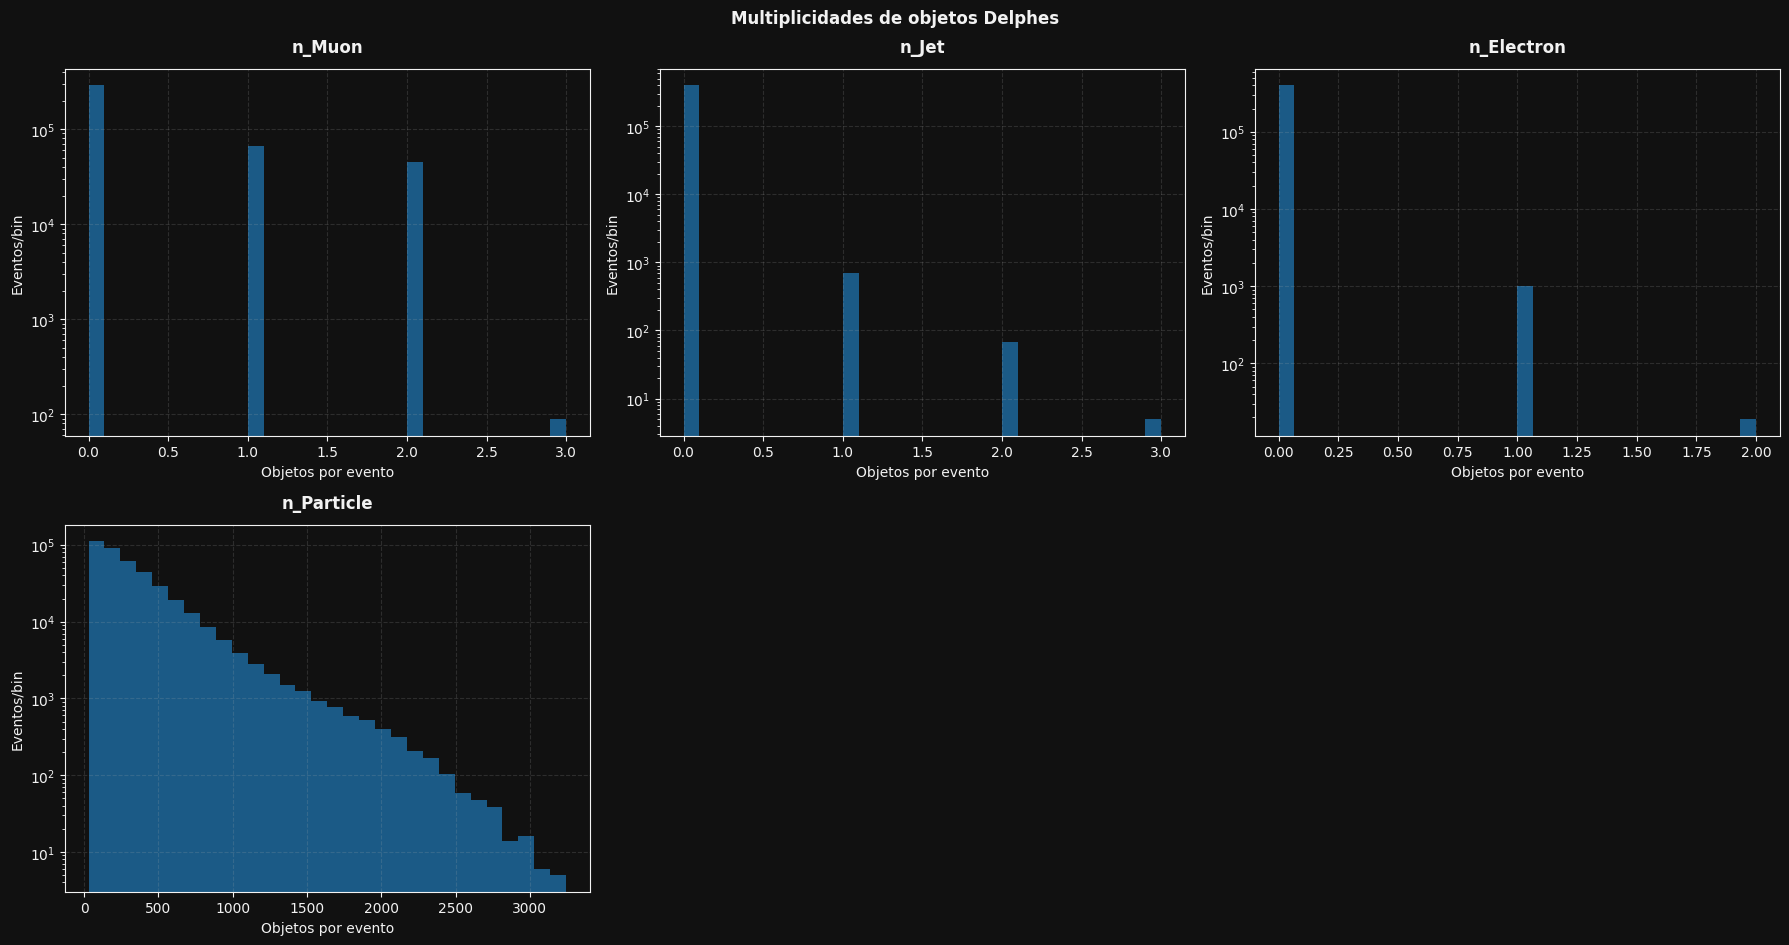

(<Figure size 1800x960 with 6 Axes>,
 array([[<Axes: title={'center': 'n_Muon'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: title={'center': 'n_Jet'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: title={'center': 'n_Electron'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>],
        [<Axes: title={'center': 'n_Particle'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: >, <Axes: >]], dtype=object))

In [15]:
pt.plot_event_multiplicities(
    df_events,
    filename='event_multiplicities_70GeV_01',
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\smf_model\c03\muon_kinematics_70GeV_01.png.


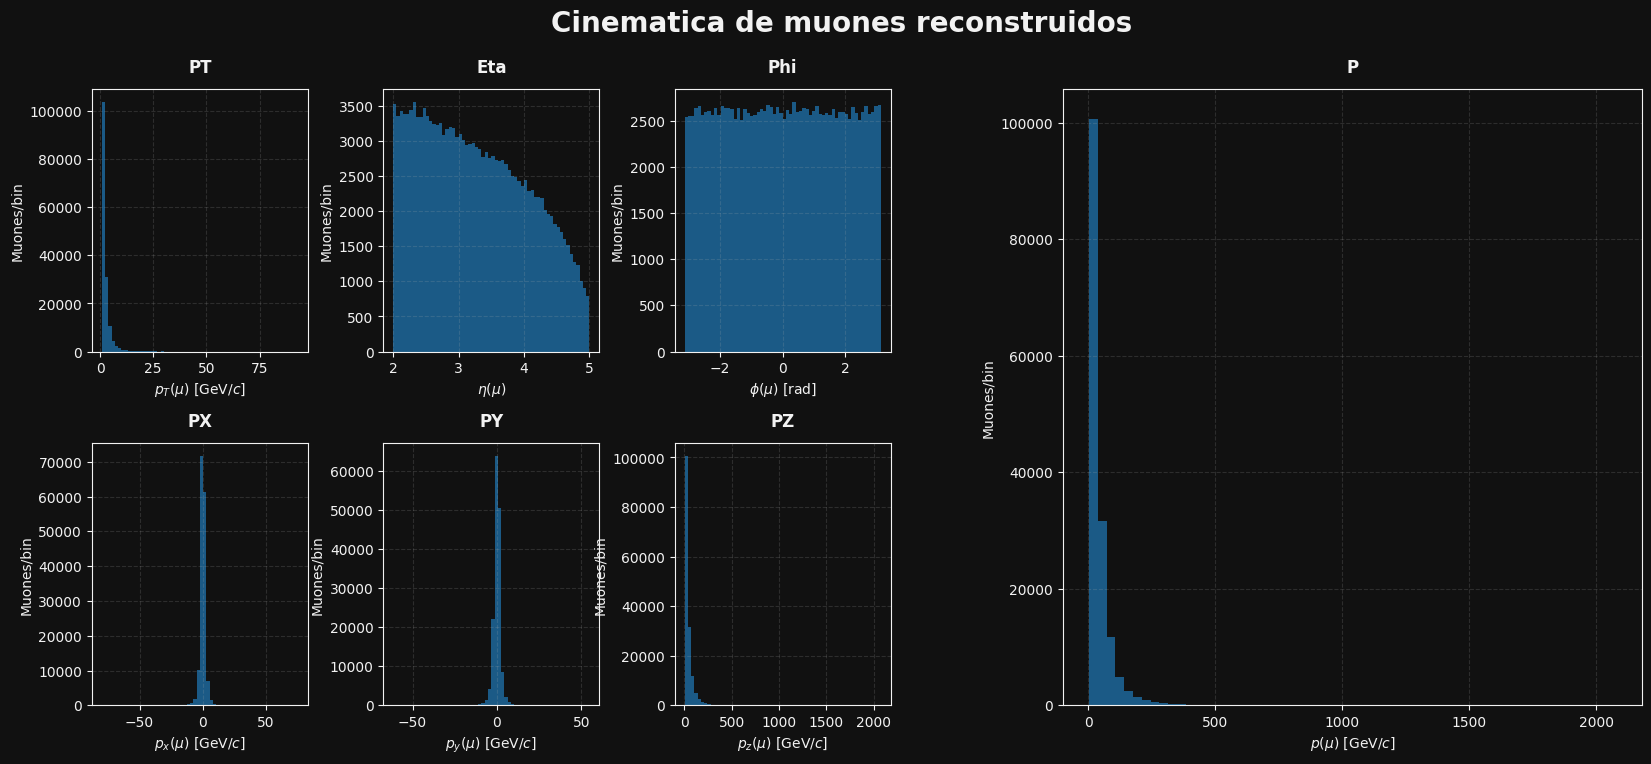

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel='$p_T(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel='$\\eta(\\mu)$', ylabel='Muones/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel='$\\phi(\\mu)$ [rad]', ylabel='Muones/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel='$p_x(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel='$p_y(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel='$p_z(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel='$p(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>})

In [16]:
pt.plot_muon_kinematics(
    df_muons, 
    bins=60, 
    filename="muon_kinematics_70GeV_01",
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\smf_model\c03\muon_kinematics_70GeV_01_cut.png.


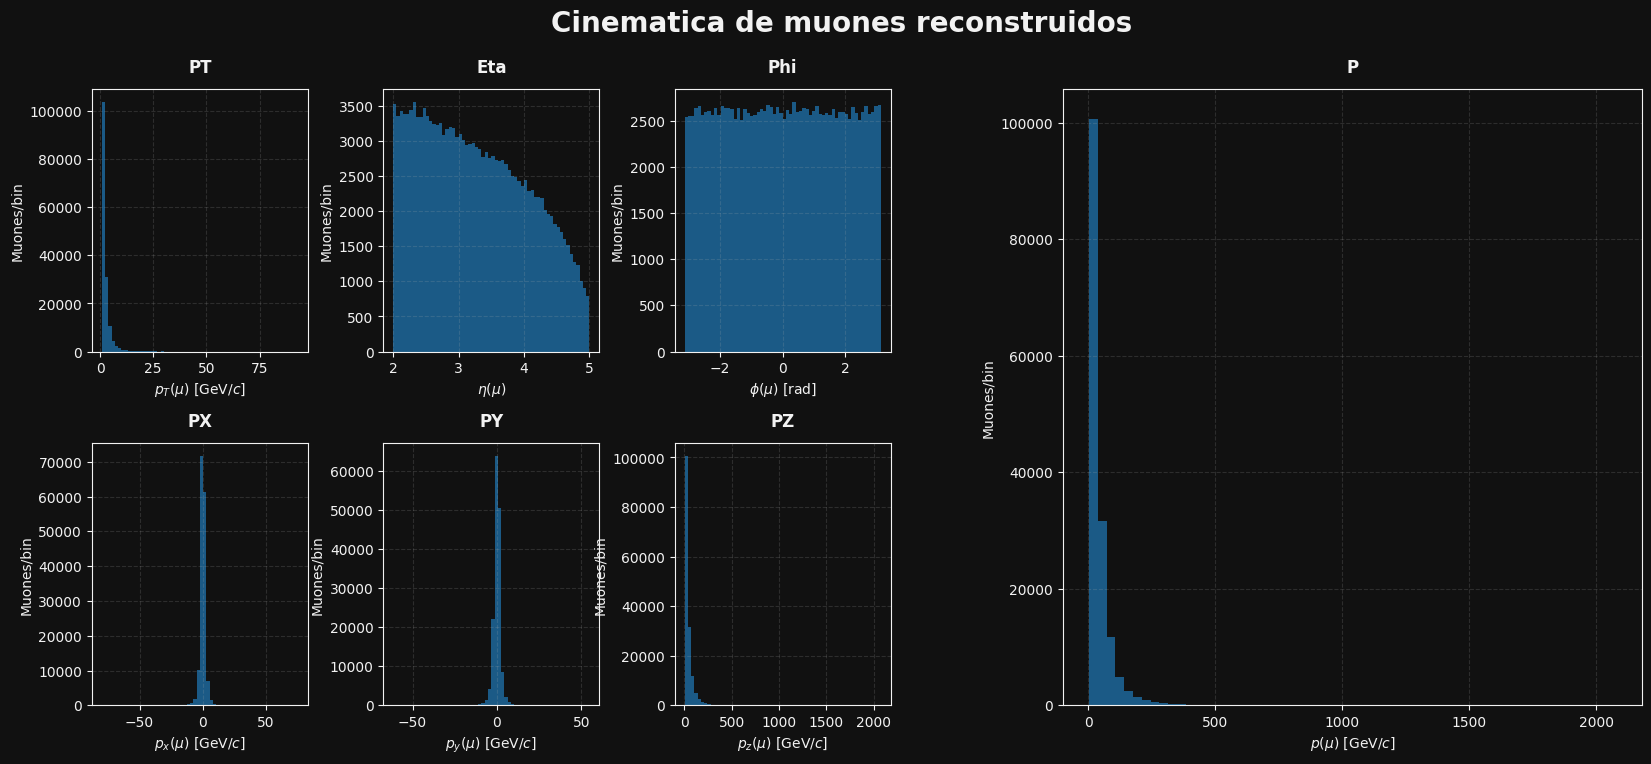

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel='$p_T(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel='$\\eta(\\mu)$', ylabel='Muones/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel='$\\phi(\\mu)$ [rad]', ylabel='Muones/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel='$p_x(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel='$p_y(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel='$p_z(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel='$p(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>})

In [17]:
pt.plot_muon_kinematics(
    cdf_muons, 
    bins=60,
    filename="muon_kinematics_70GeV_01_cut",
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\smf_model\c03\muon_kinematics_70GeV_02.png.


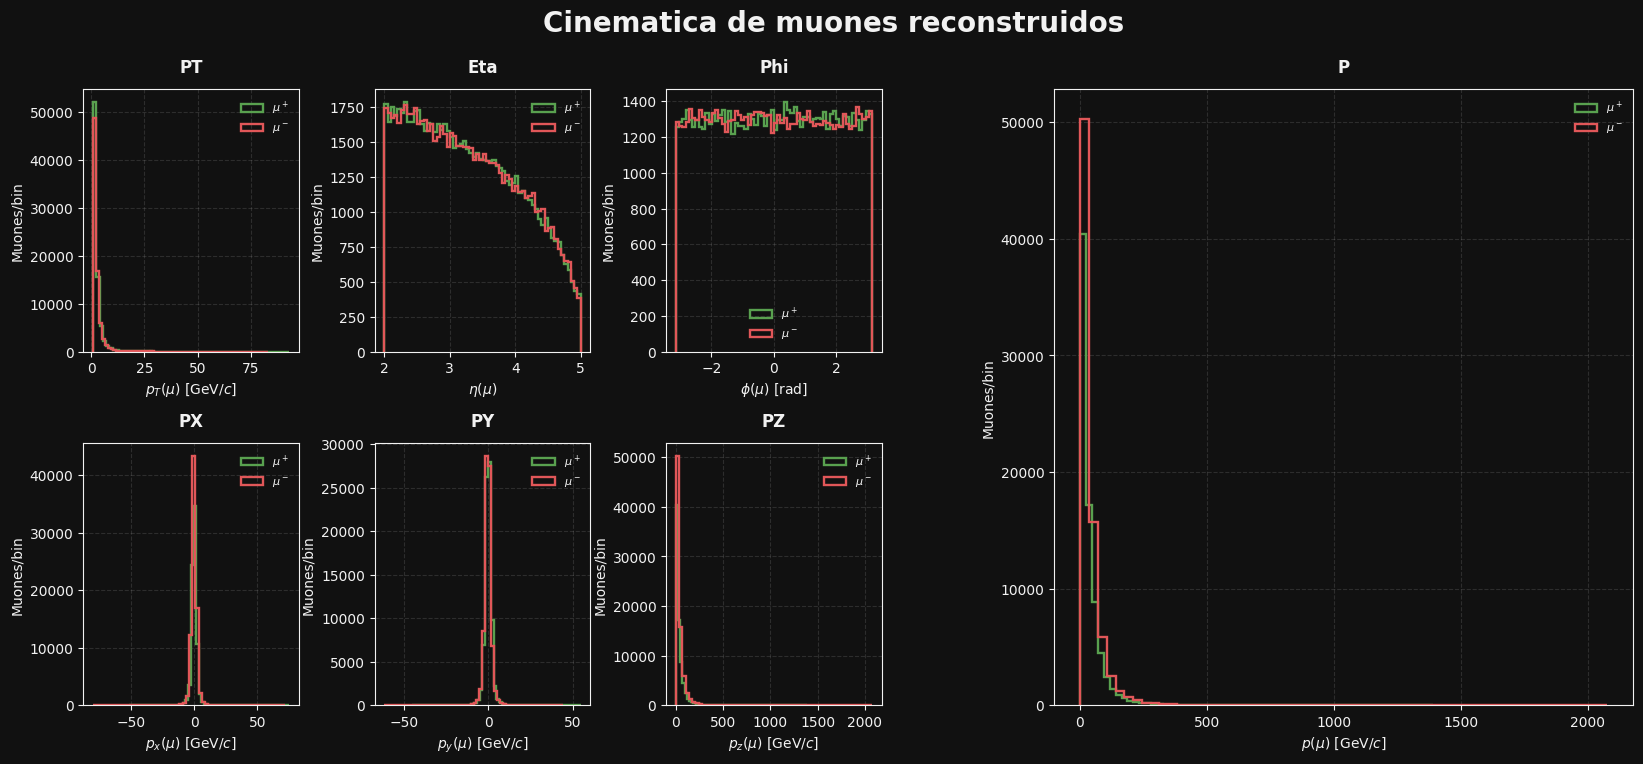

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel='$p_T(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel='$\\eta(\\mu)$', ylabel='Muones/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel='$\\phi(\\mu)$ [rad]', ylabel='Muones/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel='$p_x(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel='$p_y(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel='$p_z(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel='$p(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>})

In [18]:
pt.plot_muon_kinematics(
    df_muons, 
    bins=60, 
    split_charge=True, 
    filename="muon_kinematics_70GeV_02",
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\smf_model\c03\muon_kinematics_70GeV_02_cut.png.


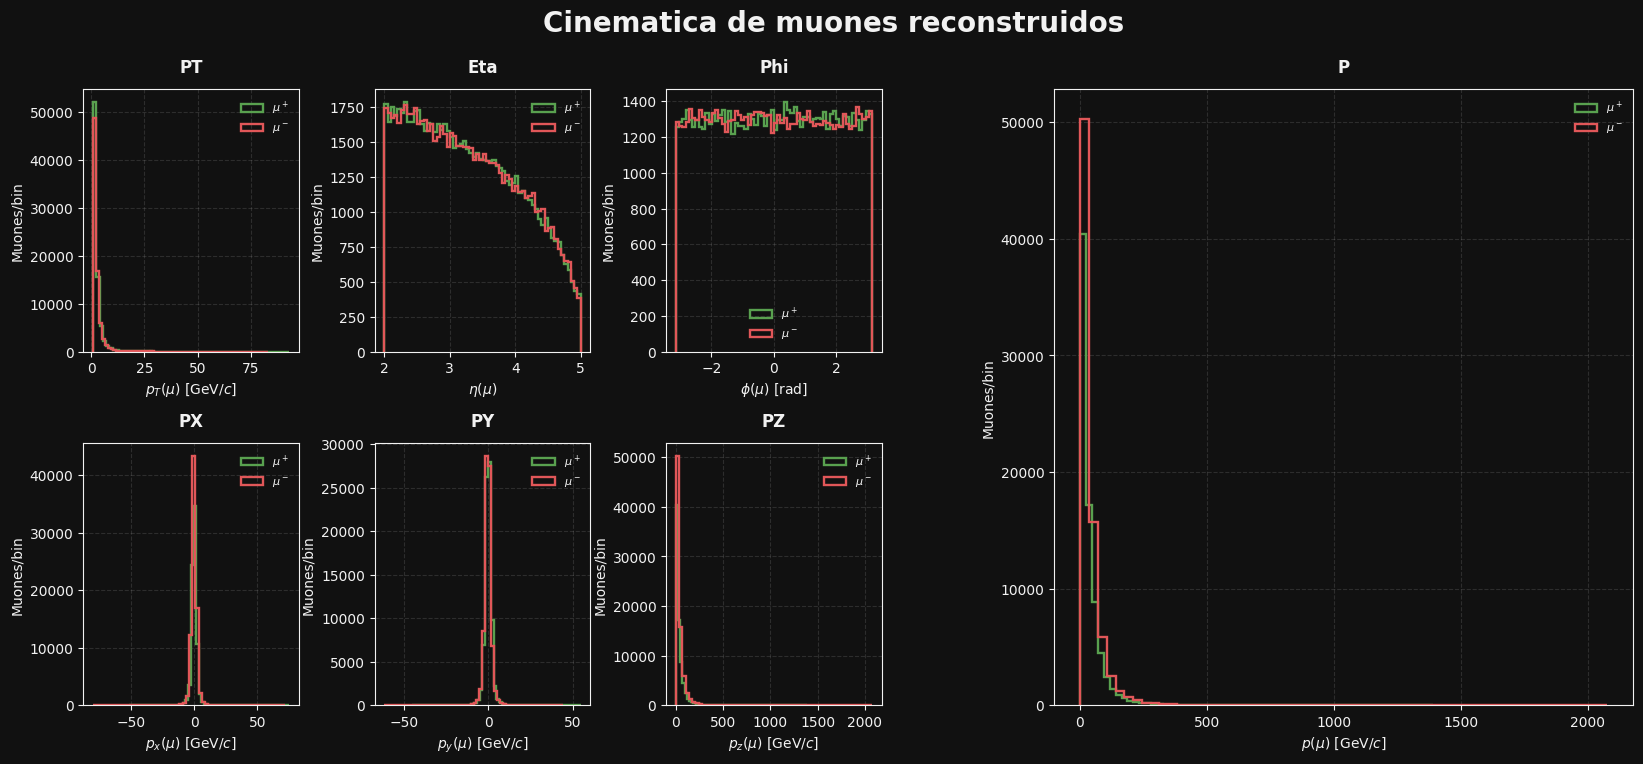

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel='$p_T(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel='$\\eta(\\mu)$', ylabel='Muones/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel='$\\phi(\\mu)$ [rad]', ylabel='Muones/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel='$p_x(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel='$p_y(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel='$p_z(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel='$p(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>})

In [19]:
pt.plot_muon_kinematics(
    cdf_muons, 
    bins=60, 
    split_charge=True,
    filename="muon_kinematics_70GeV_02_cut",
    **plot_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\smf_model\c03\dimuon_mass_70GeV_01.png.


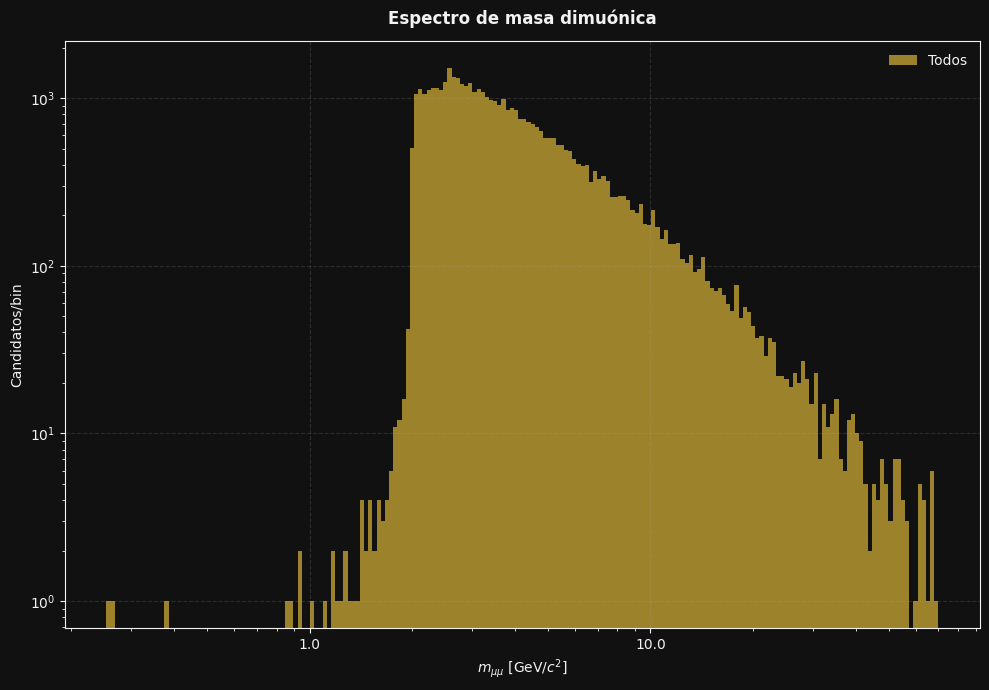

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': 'Espectro de masa dimuónica'}, xlabel='$m_{\\mu\\mu}$ [GeV/$c^2$]', ylabel='Candidatos/bin'>)

In [20]:
pt.plot_dimuon_mass(
    df_dimuons,
    bins=200, 
    log_x=True,
    log_y=True,
    mass_range=(0.0, 70.0),
    filename="dimuon_mass_70GeV_01",
    **plot_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\smf_model\c03\dimuon_mass_70GeV_01_cut.png.


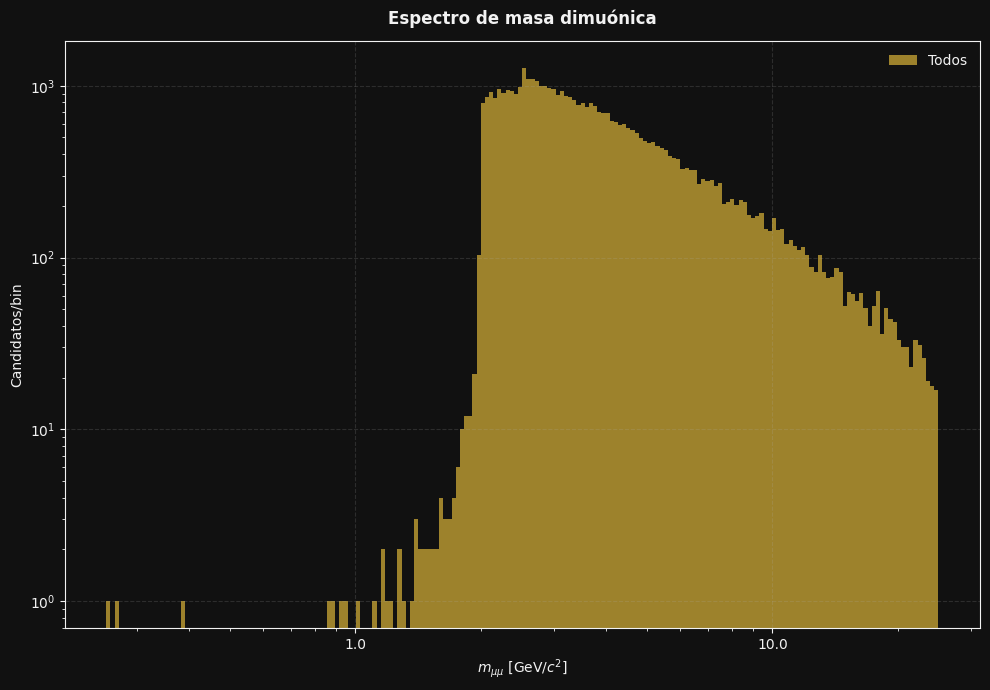

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': 'Espectro de masa dimuónica'}, xlabel='$m_{\\mu\\mu}$ [GeV/$c^2$]', ylabel='Candidatos/bin'>)

In [21]:
pt.plot_dimuon_mass(
    cdf_dimuons, 
    bins=200, 
    log_x=True,
    log_y=True,
    mass_range=(0.0, 25.0),
    filename="dimuon_mass_70GeV_01_cut",
    **plot_options
)